# Hauptkomponentenanalyse (PCA) der Primärtumoren: Wie ähneln sich die Tumortypen?

**Forschungsfrage:** Wie ähneln sich verschiedene Tumortypen in ihrer Genexpression?

Konkret: Welche Tumortypen liegen nah beieinander, welche sind klar von allen anderen abgegrenzt, und lassen sich die Ähnlichkeiten erklären
(gleiches Organ, gleicher Gewebetyp, gemeinsame Entwicklungsherkunft)? Verglichen werden die Tumortypen aus der klinischen Tabelle; Organ und Gewebetyp dienen zur Erklärung der Ergebnisse.

Die Daten kommen **fertig aufbereitet** aus `notebook_aufbereitung.ipynb`: Primärtumoren, logarithmiert, zentriert, ohne Geschlechtsgene,
die 5.000 Gene mit der größten Varianz. Die Entscheidungen dahinter und ihre Begründung stehen in `datenaufbereitung.md`.
Hier geht es nur um die Hauptkomponentenanalyse: Welche Achsen trennen die Tumortypen, und was bedeuten sie?
Die Frage, welche Tumortypen sich im Einzelnen ähneln (Nachbarschaften), beantwortet `notebook_umap.ipynb`; es baut auf den hier gespeicherten Hauptkomponenten auf.

**Voraussetzung:** `notebook_aufbereitung.ipynb` wurde einmal ausgeführt. Es erzeugt die hier verwendeten Dateien in `data/pancanatlas/`.

## Aufbau

1. Die aufbereiteten Daten laden
2. Hauptkomponentenanalyse über die Singulärwertzerlegung
3. Wie viel Varianz erklären die Hauptkomponenten?
4. Die Proben in den ersten Hauptkomponenten
5. Was bedeuten die Achsen? Die Gene mit den größten Gewichten
6. Speichern
7. Zusammenfassung und offene Fragen

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
DATA_DIR = Path("data/pancanatlas")

## 1. Die aufbereiteten Daten laden

`notebook_aufbereitung.ipynb` hat die Matrix bereits fertig vorbereitet (Einzelheiten dort und in `datenaufbereitung.md`):

- **Proben:** nur Primärtumoren (bei akuter myeloischer Leukämie aus Blut), nur vom Sequenziergerät Illumina HiSeq, ohne die als `Do_not_use` („nicht verwenden“) markierten Proben, eine Probe pro Patient.
- **Werte:** negative Werte auf 0 gesetzt, $\log_2(x + 1)$, pro Gen zentriert (Mittelwert 0), **nicht** standardisiert.
- **Gene:** ohne Gene mit fehlenden Werten, nur ausreichend exprimierte Gene, ohne die 16 Geschlechtsgene, davon die **5.000 Gene mit der größten Varianz**.

In [2]:
X = np.load(DATA_DIR / "aufbereitet_matrix.npy")                      # Proben × Gene, log2(x + 1), zentriert
meta = pd.read_csv(DATA_DIR / "aufbereitet_proben.csv", dtype={"sample_type": str, "center": str, "portion": str})
genes = pd.read_csv(DATA_DIR / "aufbereitet_gene.csv")
parameter = json.loads((DATA_DIR / "aufbereitet_parameter.json").read_text())["parameter"]
n, p = X.shape
assert len(meta) == n and len(genes) == p
assert np.abs(X.mean(axis=0)).max() < 1e-3                             # Kontrolle: jedes Gen ist zentriert
print(f"{n} Proben × {p} Gene")
print("Parameter der Aufbereitung:", {k: v for k, v in parameter.items() if k != "entferne_gene"})
print(f"Entfernte Geschlechtsgene: {len(parameter['entferne_gene'])}")

9104 Proben × 5000 Gene
Parameter der Aufbereitung: {'nur_hiseq': True, 'max_pro_typ': None, 'nan_regel': 'gene_entfernen', 'min_anteil_exprimiert': 0.5, 'k_gene': 5000, 'standardisieren': False, 'seed': 0}
Entfernte Geschlechtsgene: 16


### 1.1 Namen der Tumortypen

TCGA bezeichnet die Tumortypen mit Kürzeln wie BRCA oder LUAD. Für Legenden und Tabellen ordnen wir jedem Kürzel einen deutschen Namen zu.
Die Reihenfolge fasst verwandte Typen zusammen (zum Beispiel Gehirn, Niere, Verdauungstrakt); sie wird für die Legende verwendet.

In [3]:
NAME = {                                       # Reihenfolge: verwandte Tumortypen nebeneinander
    "GBM": "Glioblastom", "LGG": "Niedriggradiges Gliom",
    "PCPG": "Phäochromozytom/Paragangliom", "ACC": "Nebennierenrindenkarzinom",
    "UVM": "Uveamelanom (Auge)", "SKCM": "Melanom der Haut",
    "LAML": "Akute myeloische Leukämie", "DLBC": "Diffus großzelliges B-Zell-Lymphom", "THYM": "Thymom",
    "TGCT": "Keimzelltumor des Hodens",
    "KIRC": "Klarzelliges Nierenzellkarzinom", "KIRP": "Papilläres Nierenzellkarzinom", "KICH": "Chromophobes Nierenzellkarzinom",
    "LIHC": "Leberzellkarzinom", "CHOL": "Gallengangskarzinom", "PAAD": "Pankreaskarzinom",
    "STAD": "Magenkarzinom", "ESCA": "Speiseröhrenkarzinom", "COAD": "Dickdarmkarzinom", "READ": "Mastdarmkarzinom",
    "HNSC": "Plattenepithelkarzinom Kopf-Hals", "LUSC": "Plattenepithelkarzinom Lunge", "CESC": "Gebärmutterhalskarzinom",
    "BLCA": "Harnblasenkarzinom", "LUAD": "Adenokarzinom Lunge", "MESO": "Mesotheliom",
    "THCA": "Schilddrüsenkarzinom", "PRAD": "Prostatakarzinom", "BRCA": "Brustkrebs",
    "OV": "Eierstockkarzinom", "UCEC": "Endometriumkarzinom (Gebärmutter)", "UCS": "Karzinosarkom der Gebärmutter",
    "SARC": "Sarkom (Weichgewebe)",
}
TYPES = list(NAME)
assert set(meta["study"]) == set(TYPES)
print(f"{len(TYPES)} Tumortypen")
meta["study"].value_counts().rename("Proben").to_frame().T

33 Tumortypen


study,BRCA,KIRC,HNSC,LGG,LUAD,THCA,PRAD,LUSC,BLCA,STAD,...,THYM,SKCM,READ,MESO,UVM,ACC,KICH,UCS,DLBC,CHOL
Proben,1083,515,514,514,510,500,493,486,404,401,...,120,103,90,87,80,78,65,57,48,36


## 2. Hauptkomponentenanalyse (PCA) über die Singulärwertzerlegung (SVD)

Die zentrierte Matrix $X$ ($n \times p$) wird zerlegt in $X = U \Sigma V^\top$:
- Die Spalten von $V$ sind die **Hauptachsen** (Loadings): je ein Gewicht pro Gen, also die „Meta-Gene“.
- $Z = U \Sigma$ sind die **Koordinaten der Proben** auf diesen Achsen (Scores).
- Die Varianz entlang Achse $j$ ist $\sigma_j^2 / (n - 1)$.

Eine vollständige Zerlegung liefert $\min(n, p) = 5.000$ Komponenten und dauert deutlich länger. Wir brauchen nur die ersten, deshalb berechnen wir
mit `scipy.sparse.linalg.svds` nur die **100 größten** Singulärwerte (abgeschnittene SVD). Für den Anteil erklärter Varianz brauchen wir trotzdem die
**Gesamtvarianz**; die ist einfach die Summe aller quadrierten Einträge von $X$ geteilt durch $n - 1$ (Spur der Kovarianzmatrix).

In [4]:
from scipy.sparse.linalg import svds

N_COMP = 100
U, S, Vt = svds(X.astype(np.float64), k=N_COMP, random_state=0)
order = np.argsort(S)[::-1]                    # svds liefert aufsteigend sortiert
U, S, Vt = U[:, order], S[order], Vt[order]
Z = U * S                                      # Scores: Proben × Komponenten
var = S**2 / (n - 1)
total_var = (X.astype(np.float64)**2).sum() / (n - 1)
explained = var / total_var
print(f"Anzahl Komponenten: {len(S)} | Z: {Z.shape} | Vt: {Vt.shape}")
assert np.allclose(np.var(Z[:, 0], ddof=1), var[0], rtol=1e-3)   # Kontrolle: Varianz der PC1-Scores = σ₁² / (n − 1)

Anzahl Komponenten: 100 | Z: (9104, 100) | Vt: (100, 5000)


## 3. Wie viel Varianz erklären die Hauptkomponenten?

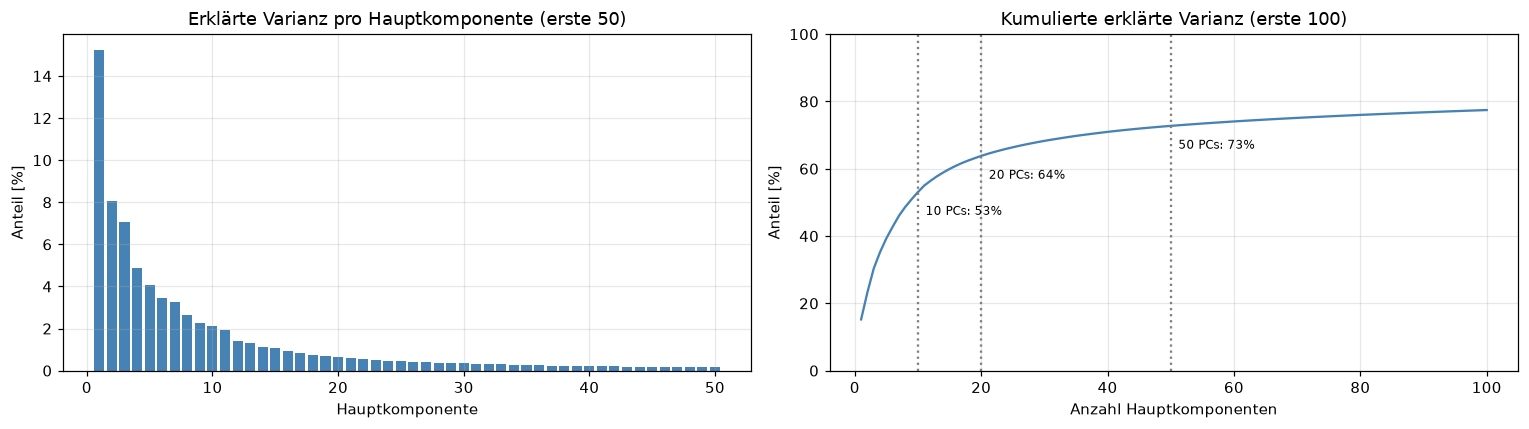

Erste   1 PCs: 15.2% der Varianz
Erste   2 PCs: 23.3% der Varianz
Erste   5 PCs: 39.3% der Varianz
Erste  10 PCs: 53.1% der Varianz
Erste  20 PCs: 63.8% der Varianz
Erste  50 PCs: 72.7% der Varianz
Erste 100 PCs: 77.4% der Varianz


In [5]:
cum = np.cumsum(explained)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(np.arange(1, 51), explained[:50] * 100, color="steelblue")
axes[0].set(title="Erklärte Varianz pro Hauptkomponente (erste 50)", xlabel="Hauptkomponente", ylabel="Anteil [%]")
axes[1].plot(np.arange(1, N_COMP + 1), cum * 100, color="steelblue")
for k in [10, 20, 50]:
    axes[1].axvline(k, color="gray", ls=":")
    axes[1].annotate(f"{k} PCs: {cum[k - 1]:.0%}", (k, cum[k - 1] * 100), xytext=(5, -15), textcoords="offset points", fontsize=8)
axes[1].set(title=f"Kumulierte erklärte Varianz (erste {N_COMP})", xlabel="Anzahl Hauptkomponenten", ylabel="Anteil [%]", ylim=(0, 100))
plt.tight_layout()
plt.show()
for k in [1, 2, 5, 10, 20, 50, 100]:
    print(f"Erste {k:3d} PCs: {cum[k - 1]:.1%} der Varianz")

**Beobachtung:**
- Die erste Hauptkomponente erklärt 15 % der Varianz, die ersten 10 zusammen 53 %, die ersten 50 rund 73 %.
  Statt 5.000 Genen genügen also wenige Dutzend Achsen für den Großteil der Struktur.
- Im ersten Durchlauf mit allen 16.711 Genen waren es 13 %, 50 % und 70 %. Die Auswahl der Gene mit der größten Varianz bündelt die Struktur etwas stärker in den ersten Achsen.
- Nach etwa 15 bis 20 Komponenten flacht die Kurve deutlich ab („Knick“). Danach bringt jede weitere Achse nur noch wenig; dort steckt vor allem
  Rauschen und Variation einzelner Proben. Laut `notebook_aufbereitung.ipynb` enthalten die Achsen ab etwa Hauptkomponente 8 auch einen kleinen Anteil von Plattenunterschieden (Batch-Effekt).
- Es gibt **keine** klare Grenze: Der Rest der Varianz verteilt sich auf sehr viele kleine Komponenten. Die Wahl der Zahl der Hauptkomponenten ist deshalb
  eine Entscheidung (siehe offene Fragen); für UMAP (`notebook_umap.ipynb`) geben wir pragmatisch die ersten 50 weiter.

## 4. Die Proben in den ersten Hauptkomponenten

Jeder Punkt ist ein Tumor, die Farbe ist sein **Tumortyp** (33 Farben, Zuordnung in der Legende).

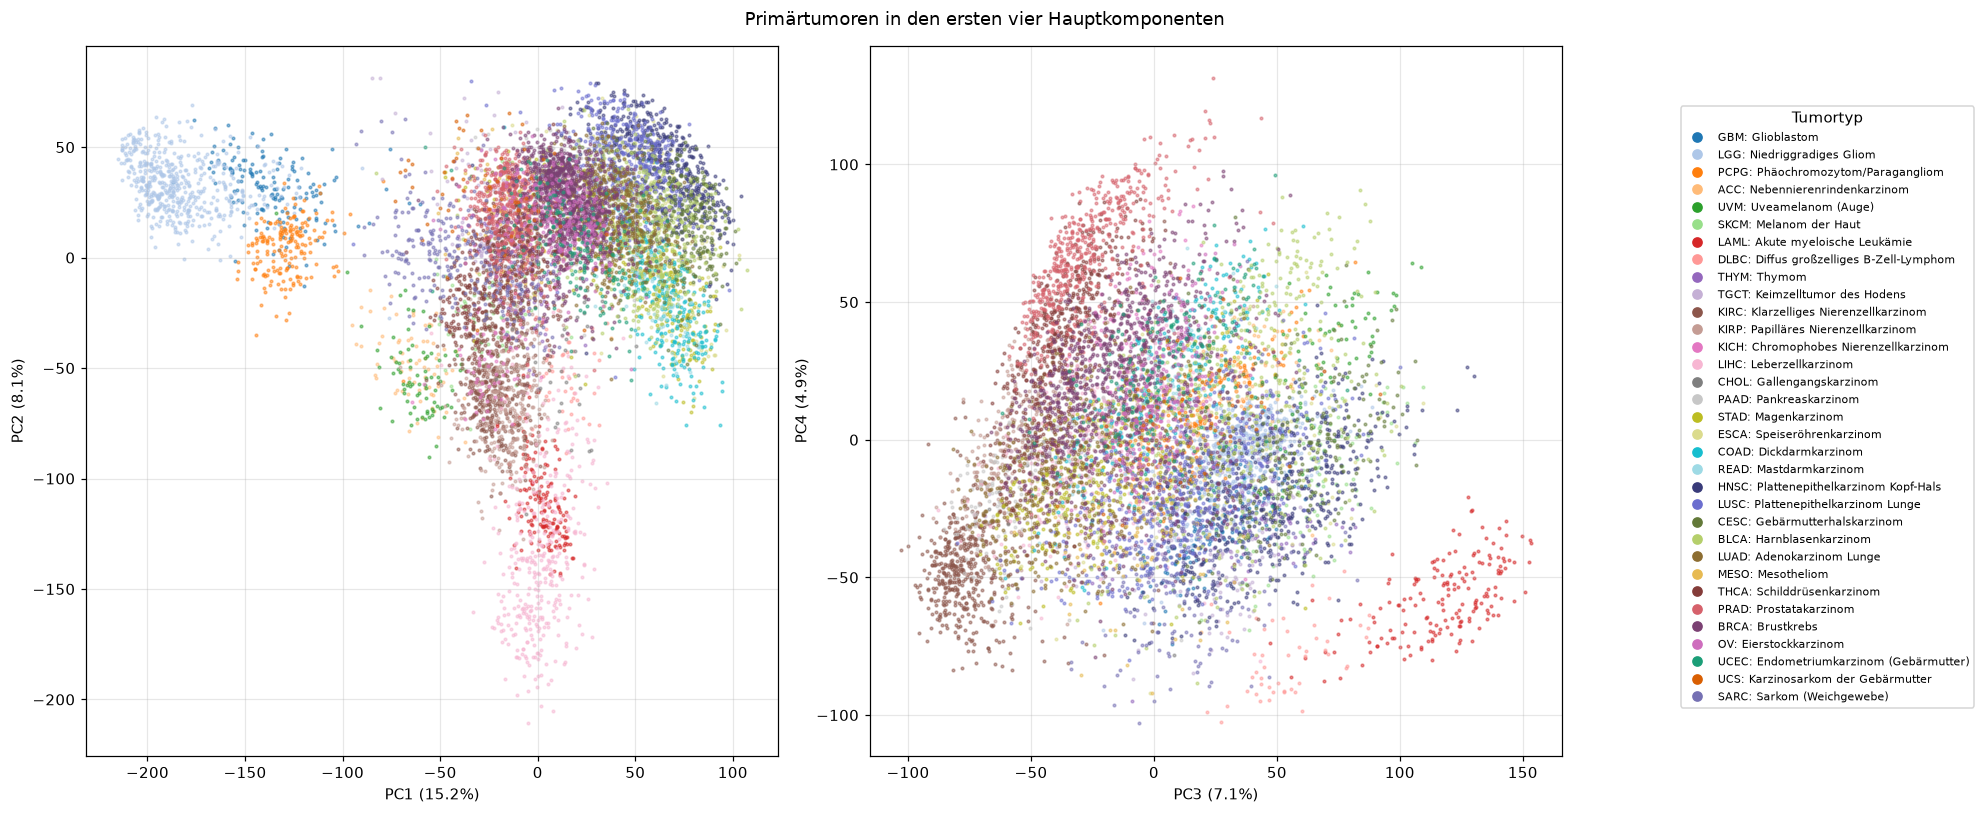

In [6]:
palette = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors[::2]) + list(plt.cm.Dark2.colors[:3])   # 33 Farben
color = dict(zip(TYPES, palette))

def pc_plot(ax, i, j):
    for s in TYPES:
        m = (meta["study"] == s).to_numpy()
        ax.scatter(Z[m, i], Z[m, j], s=3, alpha=0.5, color=color[s])
    ax.set(xlabel=f"PC{i + 1} ({explained[i]:.1%})", ylabel=f"PC{j + 1} ({explained[j]:.1%})")

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
pc_plot(axes[0], 0, 1)
pc_plot(axes[1], 2, 3)
handles = [plt.Line2D([], [], marker="o", ls="", ms=6, color=color[s], label=f"{s}: {NAME[s]}") for s in TYPES]
fig.legend(handles=handles, loc="center right", fontsize=7.5, title="Tumortyp")
fig.suptitle("Primärtumoren in den ersten vier Hauptkomponenten")
plt.tight_layout(rect=(0, 0, 0.8, 1))
plt.show()

**Beobachtungen:**
- **Hauptkomponente 1** trennt die **Hirntumoren** (niedriggradiges Gliom LGG, Glioblastom GBM) und das Phäochromozytom/Paragangliom (PCPG), schwächer das Nebennierenrindenkarzinom (ACC),
  von allen anderen. Auf der Gegenseite liegen die Karzinome, also Tumoren aus Epithelgewebe (Gebärmutterhals, Dick- und Mastdarm, Kopf-Hals).
  Die größte Variation im Datensatz ist also „Nervengewebe gegen Epithel“. (Gegenüber dem ersten Durchlauf ist das Vorzeichen umgedreht; das ist bedeutungslos, siehe Abschnitt 5.)
- **Hauptkomponente 2** hebt die **Leber** (Leberzellkarzinom LIHC) und die **akute myeloische Leukämie** (LAML) heraus, danach das papilläre Nierenzellkarzinom (KIRP).
  Am anderen Ende liegen die Plattenepithelkarzinome von Lunge (LUSC) und Kopf-Hals (HNSC) sowie der Bauchspeicheldrüsenkrebs (PAAD).
- **Hauptkomponenten 3 und 4:** Die akute myeloische Leukämie liegt weit rechts unten abseits von allem; ebenfalls rechts liegen die Melanome (Aderhaut UVM, Haut SKCM)
  und das Lymphom (DLBC). Links liegen die **Nierenkarzinome** (klarzellig KIRC, papillär KIRP) und der Bauchspeicheldrüsenkrebs, oben die **Prostata** (PRAD).
- Die meisten Karzinome **überlappen** in den ersten vier Achsen zu einer großen Wolke. Vier Achsen reichen nicht, um 33 Tumortypen zu trennen;
  die Feinstruktur steckt in weiteren Komponenten (siehe `notebook_umap.ipynb`).
- Schon hier liegen manche Tumortypen auffällig nah beieinander, zum Beispiel Speiseröhrenkrebs (ESCA), die Plattenepithelkarzinome von Kopf-Hals (HNSC) und Lunge (LUSC)
  und der Gebärmutterhalskrebs (CESC) (rechts oben im linken Bild).

## 5. Was bedeuten die Achsen? Die Gene mit den größten Gewichten

Jede Hauptachse $v_j$ (eine Zeile von $V^\top$) ist ein Einheitsvektor im Gen-Raum, also eine gewichtete Kombination aller Gene:
$$v_j = \sum_g v_{jg} \, e_g,$$
wobei $e_g$ die Achse von Gen $g$ ist. Die Gewichte $v_{jg}$ heißen **Ladungen** (*loadings*).
Der **Score** einer Probe auf PC$j$ ist dann
$$z_j = \sum_g v_{jg} \, (x_g - \bar{x}_g).$$

Ein Gen mit großem $|v_{jg}|$ geht also stark in die Achse ein: Proben, in denen dieses Gen hoch (bzw. niedrig) exprimiert ist, bekommen auf dieser
Achse einen großen positiven (bzw. negativen) Score. Die Gene mit den größten positiven und negativen Ladungen zeigen deshalb,
welchen Unterschied die Achse beschreibt. Das **Vorzeichen** einer Achse ist willkürlich ($-v$ ist genauso eine Lösung wie $v$);
nur der Gegensatz zwischen den beiden Enden zählt.

Hinweis: Da wir nicht standardisiert haben, bekommen Gene mit großer Varianz tendenziell größere Ladungen (siehe offene Fragen).

In [7]:
def top_genes(j, k=10):
    order = np.argsort(Vt[j])                                       # Ladungen von PC j, aufsteigend sortiert
    return genes["name"].to_numpy()[order[::-1][:k]], genes["name"].to_numpy()[order[:k]]

rows = []
for j in range(4):
    pos_g, neg_g = top_genes(j)
    rows.append({"PC": f"PC{j + 1}", "Ende": "+", "Gene (größte Ladungen)": ", ".join(pos_g)})
    rows.append({"PC": f"PC{j + 1}", "Ende": "−", "Gene (größte Ladungen)": ", ".join(neg_g)})
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(rows).set_index(["PC", "Ende"])

Gene (größte Ladungen)
PC  Ende                                                                          
PC1 +           CEACAM6, SFN, TMPRSS4, AGR2, LCN2, RAB25, TNS4, FXYD3, ESRP1, KRT8
    −              GFAP, PLP1, SCG3, GPM6A, ATCAY, KIF1A, BEX1, NCAN, BCAN, ELAVL3
PC2 +       SFRP2, KRT17, CDH3, FXYD3, WNT7B, CNTN1, CLCA2, TRIM29, GRHL2, COL11A1
    −              CDHR5, ALDOB, PKLR, SLC39A5, NAT8, AGXT, AMBP, PRAP1, ALB, BHMT
PC3 +       A2ML1, GJB6, CLCA2, DPF1, LASS3, TMPRSS11D, SOX15, KRT13, DLL3, CAPNS2
    −                HPN, HGD, PIGR, CLDN2, SLC34A2, CLDN3, C7, LRP2, BHMT2, ADH1B
PC4 +     AGR2, CLDN3, SPDEF, GRHL2, RAB25, C19orf46, PRR15L, ESRP1, PPP1R1B, EPN3
    −              GBP5, AIM2, S100A8, CD70, TLR8, CR1, FCRL5, SLC2A5, TFEC, ADAM6

**Beobachtungen:** Die Achsen lassen sich gut als **Gewebe- beziehungsweise Zellprogramme** lesen:

| Hauptkomponente | Ende $+$ | Ende $-$ |
|---|---|---|
| 1 | **Drüsen- und Schleimhautepithel**: `CEACAM6`, `AGR2`, `LCN2`, `KRT8` (Keratin 8) | **Nervengewebe**: `GFAP` (Glia), `PLP1` (Myelin), `BCAN` (Brevican), `ELAVL3` (Nervenzellen) |
| 2 | **Plattenepithel und Basalzellen** (`KRT17`, `CDH3`, `TRIM29`) und **Bindegewebe** (Kollagen `COL11A1`, `SFRP2`) | **Stoffwechsel von Leber und Niere**: `ALB` (Albumin), `ALDOB`, `AGXT`, `BHMT`, `CDHR5` |
| 3 | **Schleimhaut-Plattenepithel** (`KRT13`, Keratin 13; `GJB6`; `TMPRSS11D`) und Neuralleiste (`DLL3`) | **Nierenkanälchen und Drüsen**: `LRP2`, `CLDN2`, `HPN`, `PIGR` |
| 4 | **Drüsenepithel**: `AGR2`, `SPDEF`, `GRHL2` | **Immun- und Blutzellen**: `TLR8`, `S100A8` (Granulozyten), `FCRL5` (B-Zellen), `CR1`, `GBP5` |

Gegenüber dem ersten Durchlauf mit allen Genen sind es dieselben Programme; nur Vorzeichen und Reihenfolge der Gene haben sich leicht verschoben.

## 6. Speichern

Die Hauptkomponenten speichern wir für die folgenden Notebooks (UMAP, Clustering) in `data/pancanatlas/`:

| Datei | Inhalt |
|---|---|
| `pca_scores.npy` | Koordinaten der Proben auf den ersten 100 Hauptkomponenten (Proben $\times$ 100), Zeilen in der Reihenfolge von `aufbereitet_proben.csv` |
| `pca_ladungen.npy` | Ladungen (100 $\times$ Gene), Spalten in der Reihenfolge von `aufbereitet_gene.csv` |
| `pca_erklaerte_varianz.npy` | Anteil erklärter Varianz pro Hauptkomponente |

In [8]:
np.save(DATA_DIR / "pca_scores.npy", Z.astype(np.float32))
np.save(DATA_DIR / "pca_ladungen.npy", Vt.astype(np.float32))
np.save(DATA_DIR / "pca_erklaerte_varianz.npy", explained)
print(f"Gespeichert: Scores {Z.shape}, Ladungen {Vt.shape}")

Gespeichert: Scores (9104, 100), Ladungen (100, 5000)


## 7. Zusammenfassung und offene Fragen

**Ergebnis zur Forschungsfrage:** Die Hauptkomponentenanalyse zeigt, dass die Genexpression der Tumoren vor allem vom **Herkunftsgewebe** geprägt ist.
Die ersten Achsen lassen sich als Gewebe- und Zellprogramme lesen (Nervengewebe gegen Epithel, Leber und Niere, Plattenepithel, Drüsenepithel, Immunzellen):

- **Klar abgesetzt** sind schon in den ersten vier Achsen die Hirntumoren (mit dem Phäochromozytom/Paragangliom), die Leber, die akute myeloische Leukämie,
  die Nierenkarzinome, die Melanome und die Prostata.
- Die meisten **Karzinome überlappen** dagegen in einer großen Wolke. Ihre Unterschiede verteilen sich auf viele weitere Achsen.
- Tumortypen gleichen Gewebetyps liegen nah beieinander, zum Beispiel die Plattenepithelkarzinome von Speiseröhre, Kopf-Hals, Lunge und Gebärmutterhals.

Welche Tumortypen sich im Einzelnen ähneln, lässt sich aus zwei Achsen nicht ablesen. Dafür verwendet `notebook_umap.ipynb` die ersten 50 Hauptkomponenten.

**Offene Fragen zur Hauptkomponentenanalyse**

1. **Zahl der Hauptkomponenten:** Es gibt keinen klaren Knick; 50 ist eine pragmatische Wahl. Ab etwa Hauptkomponente 8 enthalten die Achsen außerdem einen kleinen Plattenanteil
   (siehe `notebook_aufbereitung.ipynb`). Ändern sich die Ergebnisse mit 20 oder 100 Hauptkomponenten?
2. **Standardisieren:** Wir haben nur zentriert. Mit Standardisierung pro Gen zählt jedes Gen gleich. Ändert das die Achsen?
3. **Genauswahl:** 5.000 Gene sind eine Setzung. Ändert sich etwas mit 1.000 Genen oder mit allen?
Ob beim Speiseröhren- und Gebärmutterhalskrebs die Adeno- und Plattenepithelkarzinome bei ihren jeweiligen Gegenstücken liegen, prüft `notebook_umap.ipynb` (Abschnitt 3.1): Ja.